<a href="https://colab.research.google.com/github/COGS108/Tutorials/blob/master/Monte_Carlo_simulation_of_coin_flip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Monte Carlo simulation

## Fair coin or not?

Lets say we have a coin in hand, and we want to test if its fair (heads equally likely as tails).  We can use probability theory because we know the distribution of coin flips.  

## Using MC to test a hypothesis

In many problems we don't know the theoretical answer but we can actually create a simulation of what a null hypothesis looks like.  Or we can permute the existing dataset to make a null hypothesis.

Here's the procedure for Monte Carlo methods

1. First, we postulate a null hypothesis ($H_o$), e.g. the coin we are looking at is a fair coin
2. Next, we simulate many draws from of our postulated process and compute a statistic on each one
3. Finally, we calculate the p-value of our real observed data against the simulated null hypothesis distribution

An alternative to step 2 is to use the empirical data iteslf.  For example: we are interested if the time of customers coming through the shop door is correlated with a particular time of day.  We take the inter-customer intervals of the real data, and we shuffle them to a random time of day.  We now have a null (random time of arrive) that still maintains the statistical properties of the real data

In [2]:
import numpy as np

num_trials = 1000000
num_flips = 16

# Simulate coin flips: 0 for tails, 1 for heads
# Each row represents a trial, each column a flip
simulated_flips = np.random.binomial(n=1, p=0.5, size=(num_trials, num_flips))

# Calculate the number of heads for each trial
num_heads_per_trial = np.sum(simulated_flips, axis=1)

print(f"Simulated {num_trials} trials of {num_flips} coin flips each.")
print(f"First 10 results (number of heads): {num_heads_per_trial[:10]}")
print(f"Mean number of heads: {np.mean(num_heads_per_trial):.2f}")
print(f"Standard deviation of number of heads: {np.std(num_heads_per_trial):.2f}")

Simulated 1000000 trials of 16 coin flips each.
First 10 results (number of heads): [10 11 11  7  8  7  7  6  6  8]
Mean number of heads: 8.00
Standard deviation of number of heads: 2.00


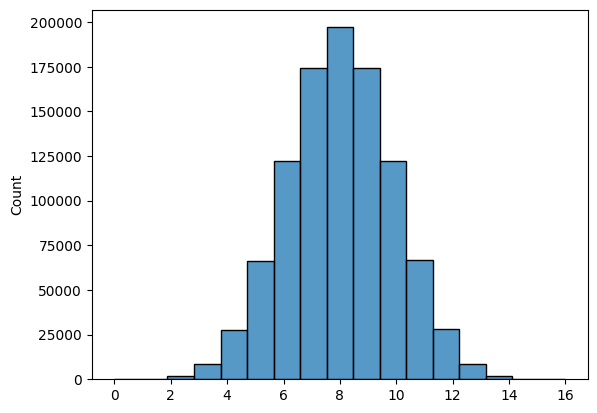

In [4]:
import seaborn as sns
sns.histplot(num_heads_per_trial, bins=17);

In [5]:
# histogram as an array of numbers rather than a plt
hist_vals = np.histogram(num_heads_per_trial, bins=17)
hist_vals[0]

array([    18,    249,   1811,   8623,  27803,  66305, 122212, 174303,
       197068, 174509, 121981,  66689,  27891,   8490,   1807,    223,
           18])

In [6]:
# probability mass (histogram values normalized by the sum of the values)
pmf = hist_vals[0] / np.sum(hist_vals[0])
pmf

array([1.80000e-05, 2.49000e-04, 1.81100e-03, 8.62300e-03, 2.78030e-02,
       6.63050e-02, 1.22212e-01, 1.74303e-01, 1.97068e-01, 1.74509e-01,
       1.21981e-01, 6.66890e-02, 2.78910e-02, 8.49000e-03, 1.80700e-03,
       2.23000e-04, 1.80000e-05])

## Is this coin fair?

Let's say we flip a real coin and get 12 heads out of 16.  Is the coin fair?

To find the p-value of the null hypothesis (the coin is fair), then we need to add up the probability mass of 12, 13, ... 16 heads plus the probability of 4, 3, ... 0

In [8]:
p_value_montecarlo = pmf[:5].sum() + pmf[-5:].sum()
print(f"Probability of getting 12 heads or weirder results from a fair coin {p_value_montecarlo:.6f}")

Probability of getting 12 heads or weirder results from a fair coin 0.076933


## Or we can use theory instead...

The probability of witnessing k heads in n flips of a coin with p=0.5 coming up heads is given by the binomial distribution



In [9]:
from scipy.stats import binom

# Probability of getting 12 heads in 16 flips with p=0.5
probability_12_heads = binom.pmf(k=12, n=16, p=0.5)
print(f"Probability of exactly 12 heads in 16 flips: {probability_12_heads:.6f}")

Probability of exactly 12 heads in 16 flips: 0.027771


In [10]:
# Probability of 12 or more heads in 16 flips with p=0.5 (P(X >= 12))
probability_12_or_more_heads = 0
for k in range(12, 17):
    probability_12_or_more_heads += binom.pmf(k=k, n=16, p=0.5)
print(f"Probability of 12 or more heads in 16 flips: {probability_12_or_more_heads:.6f}")

Probability of 12 or more heads in 16 flips: 0.038406


In [11]:
probability_4_or_fewer_heads = 0
for k in range(0, 5):
    probability_4_or_fewer_heads += binom.pmf(k=k, n=16, p=0.5)
print(f"Probability of 4 or fewer heads in 16 flips: {probability_4_or_fewer_heads:.6f}")

Probability of 4 or fewer heads in 16 flips: 0.038406


In [13]:
p_value_exact = probability_4_or_fewer_heads + probability_12_or_more_heads
print(f"Probability of getting 12 heads or weirder results from a fair coin {p_value_exact:.6f}")

Probability of getting 12 heads or weirder results from a fair coin 0.076813


In [16]:
print(f"Difference between approximate Monte Carlo method ({num_trials} trials) and the exact theoretical value: {(p_value_exact - p_value_montecarlo):.6f}")

Difference between approximate Monte Carlo method (1000000 trials) and the exact theoretical value: -0.000120
